In [2]:
load("visualize.sage")
load("surfaces.sage")
load("curves.sage")

# Curves in $\mathbb P^3$

In [6]:
K = GF(9973)

R.<x0,x1,x2,x3> = K['x0,x1,x2,x3']
X = matrix(R,[[x0],[x1],[x2],[x3]])

degree1 = 2
degree2 = 3

F1 = general_surface(degree1)
F2 = general_surface(degree2)

C = F1 + F2

print C
print C.hilbert_polynomial()

Ideal (-x0^2 - x0*x1 - x1^2 + x1*x2 - x0*x3 + 5*x2*x3, 21*x0^3 + 94*x0^2*x1 + 9*x0*x1^2 - x1^3 + 2*x1^2*x2 - x0*x2^2 - x2^3 - 4*x0^2*x3 + x0*x1*x3 + x1^2*x3 + 2*x0*x2*x3 - 8*x2^2*x3 + 2*x1*x3^2) of Multivariate Polynomial Ring in x0, x1, x2, x3 over Finite Field of size 9973
6*t - 3


In [7]:
R1.<x0,x1,x2,x3,y0,y1,y2,y3> = K[]
F1=F1.change_ring(R1)
F2=F2.change_ring(R1)
C=C.change_ring(R1)

jmat = (jacobian(F1.gens()[0], (x0,x1, x2, x3))).stack(
    (jacobian(F2.gens()[0], (x0,x1, x2, x3))))

jmat_y = jmat.stack(matrix(R1,[[y0,y1,y2,y3]]))

incidence = C + ideal(jmat_y.minors(3))
incidence = incidence.substitute(x0=1,y0=1)

tangential = incidence.elimination_ideal((x1,x2,x3)).change_ring(K[y1,y2,y3])
print "Dimension: ", tangential.dimension()
print tangential


KeyboardInterrupt: 

In [8]:
R1.<x0,x1,x2,x3,y0,y1,y2,y3,u0,u1,u2,u3> = K[]
F1=F1.change_ring(R1)
F2=F2.change_ring(R1)
F1y=F1.subs(x0=y0,x1=y1,x2=y2,x3=y3)
F2y=F2.subs(x0=y0,x1=y1,x2=y2,x3=y3)
C=C.change_ring(R1)

U = matrix(R1,[[u0],[u1],[u2],[u3]])

jmatx = (jacobian(F1.gens()[0], (x0,x1, x2, x3))).stack(
    (jacobian(F2.gens()[0], (x0,x1, x2, x3))))
jmaty = (jacobian(F1y.gens()[0], (y0,y1, y2, y3))).stack(
    (jacobian(F2y.gens()[0], (y0,y1, y2, y3))))

mat = jmatx.stack(jmaty)

incidence = F1 + F2 + F1y + F2y + ideal(mat.determinant())
incidence = incidence.subs(x0=1,y0=1)
incidence = incidence.saturation(ideal(x1-y1,x2-y2,x3-y3))[0]


#incidence = incidence + ideal((mat*U).list())

#incidence = incidence.subs(x0=1,y0=1,u0=1)

#edge = incidence.elimination_ideal((x1,x2,x3,y1,y2,y3))

#print edge


In [ ]:
incidence = incidence + ideal((mat*U).list())
edge = incidence.elimination_ideal((x1,x2,x3,y1,y2,y3))
print edge.hilbert_polynomial()

# Surfaces in $\mathbb P^3$
We consider a general surface $S$ in $\mathbb P^3$ defined by a polynomial $F \in \mathbb R[x_0,x_1,x_2,x_3]$ of degree $d$.

In [303]:
K = QQ#GF(9973)
R.<x0,x1,x2,x3> = K['x0,x1,x2,x3']

degree = 4

S_F = general_surface(degree)
F = S_F.gens()[0] 

#F = x0^3+ x1^3 + x1^2*x3 + x2^2*x3 + (x0 + 2*x1 + 3*x2 + 4*x3)^3
#S_F = ideal(F)

#F = x0^5+ x1^5 + x2^5 + x3^5 + (x0 + x1 + x2 + x3)^5 + (x0 + x1 + x2 + x3)*x0*x1*x2*x3
#S_F = ideal(F)

F = x0^4 + x1^4 + x2^4 + x3^4 + (x0 + x1 + x2 + x3)^4 + x0*x1*x2*x3
S_F = ideal(F)

#J = jacobian(F, F.variables())

print F

#print (ideal(F)+ ideal(J.minors(1))).dimension()

2*x0^4 + 4*x0^3*x1 + 6*x0^2*x1^2 + 4*x0*x1^3 + 2*x1^4 + 4*x0^3*x2 + 12*x0^2*x1*x2 + 12*x0*x1^2*x2 + 4*x1^3*x2 + 6*x0^2*x2^2 + 12*x0*x1*x2^2 + 6*x1^2*x2^2 + 4*x0*x2^3 + 4*x1*x2^3 + 2*x2^4 + 4*x0^3*x3 + 12*x0^2*x1*x3 + 12*x0*x1^2*x3 + 4*x1^3*x3 + 12*x0^2*x2*x3 + 25*x0*x1*x2*x3 + 12*x1^2*x2*x3 + 12*x0*x2^2*x3 + 12*x1*x2^2*x3 + 4*x2^3*x3 + 6*x0^2*x3^2 + 12*x0*x1*x3^2 + 6*x1^2*x3^2 + 12*x0*x2*x3^2 + 12*x1*x2*x3^2 + 6*x2^2*x3^2 + 4*x0*x3^3 + 4*x1*x3^3 + 4*x2*x3^3 + 2*x3^4


In [54]:
plot_surf(F)

### Image contour
We observe the surface with a perspective projection.

Ideal (272192000000*u0^6 - 1491998400000*u0^5*u1 + 1696523320000*u0^4*u1^2 + 8893903140000*u0^3*u1^3 + 13366762724300*u0^2*u1^4 + 8732208561660*u0*u1^5 + 2731856948163*u1^6 - 902150400000*u0^5*u2 + 1357417440000*u0^4*u1*u2 + 28212579928000*u0^3*u1^2*u2 + 52942214041200*u0^2*u1^3*u2 + 42065623841380*u0*u1^4*u2 + 13858167179034*u1^5*u2 - 485045760000*u0^4*u2^2 + 29013682608000*u0^3*u1*u2^2 + 92990546980800*u0^2*u1^2*u2^2 + 95291120943720*u0*u1^3*u2^2 + 37605573990515*u1^4*u2^2 + 10027335744000*u0^3*u2^3 + 75754685160000*u0^2*u1*u2^3 + 119159040663760*u0*u1^2*u2^3 + 59265588406428*u1^3*u2^3 + 23576988806400*u0^2*u2^4 + 79016457726720*u0*u1*u2^4 + 58257916454068*u1^2*u2^4 + 20909639596800*u0*u2^5 + 31825946401344*u1*u2^5 + 7068159249664*u2^6) of Multivariate Polynomial Ring in x0, x1, x2, x3, u0, u1, u2 over Rational Field


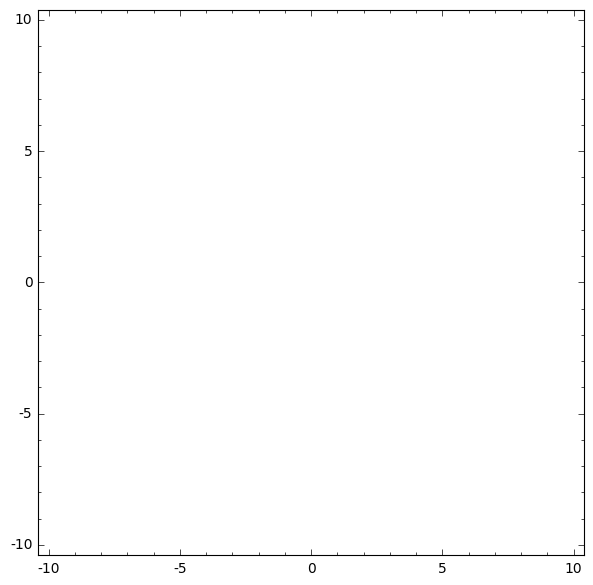

In [44]:
R2.<x0,x1,x2,x3,u0,u1,u2> = K['x0,x1,x2,x3,u0,u1,u2']

P = vector([2,-1/10,0,1])
proj_matrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])


X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S_F = S_F.change_ring(R2)

#incidence_ideal = S_F + ideal((proj_matrix*X).augment(U).minors(3))
incidence_ideal = S_F + ideal((proj_matrix*X-U).list())

ramification = incidence_ideal + ideal(jacobian(incidence_ideal.gens(),(x0,x1,x2,x3)).minors(4))

outline = ramification.saturation(ideal(x0, x1, x2, x3))[0]
outline = outline.elimination_ideal((x0, x1, x2, x3))
#outline = outline.change_ring(QQ[u0,u1,u2])

print outline

g = plot_curve(outline,'surf')
g.show()

### Hurwitz complex
The Hurwitz complex is the union of tangent lines.

In [153]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = K[]

# two points on u0x0+u1x1+u2x2=0
P = vector(R1,[p01,0,-p12,-p13])
Q = vector(R1,[0, p01, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]

c=poly.polynomial(t).coefficients()

disc=load('discriminants/disc%d_2' %(degree))
v = disc.ring().gens()
disc = disc.change_ring(K[v])
sub_dict = dict(zip((disc.ring()).gens(),c))
hurwitz = (disc.subs(sub_dict)).change_ring(R1)

hurwitz = hurwitz + ideal(p01*p23-p02*p13+p03*p12)#.change_ring(R2)


hurwitz = hurwitz.saturation(ideal(p01))[0]
hurwitz = ideal(hurwitz.groebner_basis())
hurwitz = (hurwitz.homogenize(p01)).change_ring(K[p01, p02, p03, p12, p13, p23])

print "Degree of Hurwitz: ", hurwitz.gens()[0].degree()
print hurwitz

KeyboardInterrupt: 

### Event surfaces
We can compute a representation of the flecnodal, cusp crossing, and tritangent surfaces as curves in ${\rm Gr}(1,\mathbb P^3)$.

In [304]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = K[]

event_type = '4'

P = vector(R1,[1,0,-p12,-p13])
Q = vector(R1,[0, 1, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]


c=poly.polynomial(t).coefficients()
disc=load("discriminants/disc%d_%s" %(degree,event_type))
v = disc.ring().gens()
disc = disc.change_ring(K[v])

sub_dict = dict(zip((disc.ring()).gens(),c))


event_surface = (disc.subs(sub_dict)).change_ring(R1)
event_surface = ideal(event_surface)+ideal(1*p23-p02*p13+p03*p12) #.change_ring(R2)

#flecnodal = flecnodal.saturation(ideal(p01))[0]
event_surface = ideal(event_surface.groebner_basis())


event_surface = (event_surface.homogenize(p01)).change_ring(K[p01, p02, p03, p12, p13, p23])
print "Degree of Surface: ", event_surface.hilbert_polynomial().coefficients()[1]
print event_surface.hilbert_polynomial()

Degree of Surface:  -60
20*t^2 - 60*t + 46


In [299]:
save(event_surface,'event_surfaceF')

In [301]:
from sage.libs.singular.function_factory import singular_function
minbase = singular_function('minbase')

event_surface = ideal(minbase(event_surface))

print(len(event_surface.gens()))
gnum = [0] * 30
for g in event_surface.gens():
    deg_g = g.degree()
    gnum[deg_g]+=1
for i in range(len(gnum)):
    print i, gnum[i]

11
0 0
1 0
2 1
3 0
4 0
5 0
6 10
7 0
8 0
9 0
10 0
11 0
12 0
13 0
14 0
15 0
16 0
17 0
18 0
19 0
20 0
21 0
22 0
23 0
24 0
25 0
26 0
27 0
28 0
29 0


In [293]:
disc=load("discriminants/disc%d_%s" %(5,'4'))
#print disc

from sage.libs.singular.function_factory import singular_function
minbase = singular_function('minbase')


print minbase(disc)

#print(len(disc.gens()))
gnum = [0] * 30
for g in disc.gens():
    deg_g = g.degree()
    gnum[deg_g]+=1
for i in range(len(gnum)):
    print i, gnum[i]

[3*a3^2 - 8*a2*a4 + 20*a1*a5, a2*a3 - 6*a1*a4 + 50*a0*a5, 3*a2^2 - 8*a1*a3 + 20*a0*a4]
0 0
1 0
2 3
3 2
4 1
5 0
6 0
7 0
8 0
9 0
10 0
11 0
12 0
13 0
14 0
15 0
16 0
17 0
18 0
19 0
20 0
21 0
22 0
23 0
24 0
25 0
26 0
27 0
28 0
29 0


We next compute the *parabolic surface*.

In [225]:
R1.<x0, x1, x2, x3, y0, y1, y2, y3, p01, p02, p03, p12, p13, p23> = K[]

F1 = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(F1, (x0,x1, x2, x3)), (x0, x1, x2, x3))


X = matrix(R1,[[x0], [x1], [x2], [x3]])
Y = matrix(R1,[[y0], [y1], [y2], [y3]])

XY = X.augment(Y)
XYmin = XY.minors(2)

I = ideal(F1) + ideal(H.determinant()) + ideal((H*Y).list()) + ideal(p01-XYmin[0],
    p02-XYmin[1],p03-XYmin[2],p12-XYmin[3],p13-XYmin[4],p23-XYmin[5])

parabolic = I.elimination_ideal((x0, x1, x2, x3, y0, y1, y2, y3))

parabolic = parabolic.change_ring(K[p01, p02, p03, p12, p13, p23])
print parabolic.hilbert_polynomial()

KeyboardInterrupt: 

In [ ]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t, s> = K[]
Ft = (ideal(F).change_ring(R1)).gens()[0]
J = jacobian(Ft, (x0,x1, x2, x3))
H = jacobian(jacobian(Ft, (x0,x1, x2, x3)), (x0, x1, x2, x3))

X = matrix(R1,[[x0], [x1], [x2], [x3]])

P = matrix(R1,[[1,0,-p12,-p13]]).transpose()
Q = matrix(R1,[[0, 1, p02, p03]]).transpose()

X1 = P+t*Q
X2 = P+s*Q


dict_poly = dict(zip(X.list(),X1.list()))
J1 = J.subs(dict_poly)
F1 = Ft.subs(dict_poly)

dict_poly = dict(zip(X.list(),X2.list()))
J2 = J.subs(dict_poly)
F2 = Ft.subs(dict_poly)

minor_ideal = ideal((J1.stack(J2)).minors(2))
#minor_ideal2 = minor_ideal.quotient(ideal(s-t))
glist = [R1(g/(s-t)) for g in minor_ideal.gens()]
minor_ideal2 = ideal(glist)
#print minor_ideal2
#print minor_ideal == minor_ideal2


edge = ideal(F1) + ideal(F2)

## + event_surface.change_ring(R1)

edge = edge.saturation(s-t)[0]

edge = edge + minor_ideal2 + event_surface.change_ring(R1)

#edge = edge.saturation(p01)[0]

edge = edge.elimination_ideal((s,t)) #+ ideal(1*p23-p02*p13+p03*p12)

edge = ideal(edge.groebner_basis())
edge = edge.homogenize(p01)

edge = edge.change_ring(K[p01, p02, p03, p12, p13, p23])


print edge.hilbert_polynomial()

In [ ]:
minor_ideal2 = minor_ideal.quotient

In [226]:
R1.<x0, x1, x2, x3, y0, y1, y2, y3, p01, p02, p03, p12, p13, p23> = K[]
Fx = (ideal(F).change_ring(R1)).gens()[0]
J = jacobian(Fx, (x0,x1, x2, x3))
H = jacobian(jacobian(Fx, (x0,x1, x2, x3)), (x0, x1, x2, x3))

X = matrix(R1,[[x0], [x1], [x2], [x3]])
Y = matrix(R1,[[y0], [y1], [y2], [y3]])



dict_poly = dict(zip(X.list(),Y.list()))
J1 = J.subs(dict_poly)
F1 = Fx.subs(dict_poly)

XY = X.augment(Y)
XYmin = XY.minors(2)


I = ideal(Fx)+ideal(F1) + ideal((J.stack(J1)).minors(2)) + ideal(p01-XYmin[0],
    p02-XYmin[1],p03-XYmin[2],
        p12-XYmin[3],p13-XYmin[4],p23-XYmin[5]) + ideal(p01*p23-p02*p13+p03*p12) + event_surface.change_ring(R1)
    



edge = I.elimination_ideal((x0, x1, x2, x3, y0, y1, y2, y3))

edge = parabolic.change_ring(K[p01, p02, p03, p12, p13, p23])
print edge.hilbert_polynomial()

#

KeyboardInterrupt: 

In [409]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23> = K[]
Ft = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(Ft, (x0,x1, x2, x3)), (x0, x1, x2, x3))

X = matrix(R1,[[x0], [x1], [x2], [x3]])
#P = matrix(R1,[[p01,0,-p12,-p13]]).transpose()
#Q = matrix(R1,[[0, p01, p02, p03]]).transpose()
P = matrix(R1,[[0,p23,-p13,p12],[-p23,0,p03,-p02],[p13,-p03,0,p01],[-p12,p02,-p01,0]])

parabolic = parabolic.change_ring(R1)

I = parabolic + ideal((P*X).list())
I = I.substitute(p01 = 1)

parabolic_surface = I.elimination_ideal((p02, p03, p12, p13, p23))

print parabolic_surface

KeyboardInterrupt: 

In [251]:
v=['a%d%d' %(i,j) for i in xrange(5) for j in xrange(5)]
print v
v.append('t')
v.append('s')
v.append('s1')
v.append('t1')
R=PolynomialRing(QQ, v)
R.inject_variables()
poly = sum([R('a%d%d' %(i,j))*t^i*s^j for i in xrange(5) for j in xrange(5)])
print poly

poly1 = poly.subs(s=s1,t=t1)

J = jacobian(poly, (s,t))
J1 = J.subs(s=s1,t=t1)

I = ideal(poly,poly1) + ideal(J.list()) + ideal(J1.list())

I = I.saturation(ideal(s-t))

['a00', 'a01', 'a02', 'a03', 'a04', 'a10', 'a11', 'a12', 'a13', 'a14', 'a20', 'a21', 'a22', 'a23', 'a24', 'a30', 'a31', 'a32', 'a33', 'a34', 'a40', 'a41', 'a42', 'a43', 'a44']
Defining a00, a01, a02, a03, a04, a10, a11, a12, a13, a14, a20, a21, a22, a23, a24, a30, a31, a32, a33, a34, a40, a41, a42, a43, a44, t, s, s1, t1
a44*t^4*s^4 + a43*t^4*s^3 + a34*t^3*s^4 + a42*t^4*s^2 + a33*t^3*s^3 + a24*t^2*s^4 + a41*t^4*s + a32*t^3*s^2 + a23*t^2*s^3 + a14*t*s^4 + a40*t^4 + a31*t^3*s + a22*t^2*s^2 + a13*t*s^3 + a04*s^4 + a30*t^3 + a21*t^2*s + a12*t*s^2 + a03*s^3 + a20*t^2 + a11*t*s + a02*s^2 + a10*t + a01*s + a00


KeyboardInterrupt: 

In [ ]:
print poly.polynomial

In [ ]:
R1.<x0, x1, x2, x3, y0, y1, y2, y3, z0, z1, z2, z3,t> = K[]

F1 = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(F1, (x0,x1, x2, x3)), (x0, x1, x2, x3))


X = matrix(R1,[[x0], [x1], [x2], [x3]])
Y = matrix(R1,[[y0], [y1], [y2], [y3]])
Z = matrix(R1,[[z0], [z1], [z2], [z3]])


#I = ideal(F1) + ideal(H.determinant()) + ideal((H*Y).list()) + ideal((Z-(Y+t*X)).list())
I = ideal(F1) + ideal(H.determinant()) + ideal((H*(Z+t*X)).list())

#parabolic = I.elimination_ideal((x0, x1, x2, x3, y0, y1, y2, y3,t))
parabolic = I.elimination_ideal((x0, x1, x2, x3,t))


parabolic = parabolic.change_ring(K[z0, z1, z2, z3])
print parabolic.hilbert_polynomial()

In [43]:
R1.<x0, x1, x2, x3, z0, z1, z2, z3> = K[]

F1 = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(F1, (x0,x1, x2, x3)), (x0, x1, x2, x3))
J = jacobian(F1, (x0,x1, x2, x3)).transpose()


X = matrix(R1,[[x0], [x1], [x2], [x3]])
Z = matrix(R1,[[z0], [z1], [z2], [z3]])

F1 = F1.subs(x0=1)

#I = ideal(F1) + ideal(H.determinant()) + ideal((H*Y).list()) + ideal((Z-(Y+t*X)).list())
I = ideal(F1) + ideal((H*Z-degree*J).list()) #+ ideal(H.determinant()) +


I = I.subs(x0=1)
I = I.subs(z0=1)
#parabolic = I.saturation(x0)[0]
#parabolic = I.saturation(x0)

parabolic = I.elimination_ideal((x0, x1, x2, x3))


parabolic = parabolic.homogenize(z0)

parabolic = parabolic.change_ring(K[z0, z1, z2, z3])


print parabolic.hilbert_polynomial()
print parabolic.dimension()

30*t - 24
2


In [305]:
R1.<x0, x1, x2, x3, y0, y1, y2, y3, z0, z1, z2, z3, t> = K[]

F1 = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(F1, (x0,x1, x2, x3)), (x0, x1, x2, x3))


X = matrix(R1,[[x0], [x1], [x2], [x3]])
Y = matrix(R1,[[y0], [y1], [y2], [y3]])
Z = matrix(R1,[[z0], [z1], [z2], [z3]])
S = matrix(R1,[[1],[t]])
#mat0 = X.augment(Y).augment(Z)
mat = X.augment(Y)*S


# parabolic curve
parabolic_curve = ideal(F1) + ideal(H.determinant())


# edge regression:
incidence_regression = parabolic_curve + ideal((H*Y).list())
edge_regression = incidence_regression.subs(x0=1).elimination_ideal((x1,x2,x3))

# parabolic surface:
incidence_regression = incidence_regression.substitute(x0=1,y0=1)
incidence_parabolic = incidence_regression + ideal((Z-mat).list()) #ideal(Z.augment(mat).minors(2))#
#incidence_parabolic = incidence_parabolic.saturation(ideal((X-Y).list()))[0]
incidence_parabolic = ideal(F1) + ideal((H*(X+t*Z)).list())
incidence_parabolic = incidence_parabolic.substitute(x0=1,z0=1)

#incidence_parabolic = incidence_parabolic.substitute(x0=1,y0=1)
#incidence_parabolic = incidence_parabolic.saturation(ideal(x1-y1,x2-y2,x3-y3))[0]


incidence_parabolic = incidence_parabolic.elimination_ideal(t)
incidence_parabolic = incidence_parabolic.elimination_ideal((x1,x2,x3))
#incidence_parabolic = incidence_parabolic.elimination_ideal((y1,y2,y3))
#incidence = incidence.elimination_ideal((z1,z2,z3))

parabolic_surface = incidence_parabolic.substitute(z0=1).change_ring(K[z1,z2,z3])

print parabolic_surface

#parabolic = parabolic.change_ring(K[z1,z2,z3])
#parabolic = parabolic.change_ring(K[x1,x2,x3])
#parabolic = parabolic.change_ring(K[y1,y2,y3])

#parabolic = parabolic.homogenize(z0).change_ring(K[z0,z1,z2,z3])

#parabolic = ideal(parabolic.groebner_basis())
#parabolic = parabolic.homogenize(x0)

#print len(parabolic.gens())




#print parabolic.hilbert_polynomial()

KeyboardInterrupt: 

In [362]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t, s> = K[]
Ft = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(Ft, (x0,x1, x2, x3)), (x0, x1, x2, x3))

X = matrix(R1,[[x0], [x1], [x2], [x3]])
P = matrix(R1,[[p01,0,-p12,-p13]]).transpose()
Q = matrix(R1,[[0, p01, p02, p03]]).transpose()

X1 = P+t*Q
X2 = P+s*Q

dict_poly = dict(zip(X.list(),Xline.list()))
H1 = H.subs(dict_poly)
F1 = Ft.subs(dict_poly)

poly = Ft.subs(dict_poly)
polyD = poly.derivative(t)
polyD2 = polyD.derivative(t)


#parabolic = ideal(poly,polyD,polyD2,H1.determinant())+ideal(1*p23-p02*p13+p03*p12)
parabolic = ideal(H1.determinant(),F1)+ideal((H1*X2).list())+ideal(1*p23-p02*p13+p03*p12)

parabolic = parabolic.elimination_ideal((t,s))
parabolic = (parabolic.homogenize(p01)).change_ring(K[p01,p02,p03,p12,p13,p23])

#parabolic = parabolic.radical()
print parabolic



Ideal (p03*p12 - p02*p13 + p01*p23) of Multivariate Polynomial Ring in p01, p02, p03, p12, p13, p23 over Finite Field of size 9973


In [380]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t, s> = K[]
Ft = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(Ft, (x0,x1, x2, x3)), (x0, x1, x2, x3))

X = matrix(R1,[[x0], [x1], [x2], [x3]])
P = matrix(R1,[[p01,0,-p12,-p13]]).transpose()
Q = matrix(R1,[[0, p01, p02, p03]]).transpose()

X1 = P+t*Q
X2 = P+s*Q


dict_poly = dict(zip(X.list(),X1.list()))
H1 = H.subs(dict_poly)
F1 = Ft.subs(dict_poly)


## parabolic lines
#parabolic_lines = ideal(H1.determinant(),F1)+ideal(p01*p23-p02*p13+p03*p12)
#parabolic_lines = parabolic_lines.elimination_ideal(t)

#parabolic_lines = parabolic_lines.change_ring(K[p01, p02, p03, p12, p13, p23])

#print parabolic_lines.dimension()
#print parabolic_lines


## parabolic lines

edge_lines = ideal(F1)+ideal(H1.determinant())+ideal((H1*X2).list())+ideal(p01*p23-p02*p13+p03*p12)
edge_lines = edge_lines.elimination_ideal((s,t))

edge_lines = edge_lines.change_ring(K[p01, p02, p03, p12, p13, p23])

print edge_lines.dimension()
print edge_lines.hilbert_polynomial()





4
2/3*t^3 + 2*t^2 + 157/3*t - 224


30*t - 45


In [372]:
R3.<p01, p02, p03, p12, p13, p23> = K[]

line = {'01':1, '02':0, '03':0, '12':0, '13':0, '23':0}

line_meet = ideal(p01*line['23']-p02*line['13']+p03*line['12'] + p12*line['03'] 
                  - p13*line['02'] + p23*line['01']).change_ring(K[p01, p02, p03, p12, p13, p23])

line_meet_event = event_surface + line_meet

print line_meet_event.hilbert_polynomial()

#print line_meet_event

#print line_meet_event.minimal_associated_primes()
line_meet_event = line_meet_event.subs(p02=1)
#line_meet_event = line_meet_event.elimination_ideal((p01, p03, p12, p23))
#print line_meet_event

#real_line_meet = real_line_meet.change_ring(K[p23])
#real_line_meet.parent()
#print (real_line_meet.gens()[0]).degree(p23)
real_line_meet = line_meet_event.change_ring(K[p01, p03, p12, p13, p23]).variety(RR)
#print "Number of real double lines: ", len(real_line_meet)
print len(real_line_meet)

TypeError: right must be a system over same ring as self.

In [282]:
R1.< x0, x1, x2, x3, u0, u1, u2, u3 > = QQ['x0,x1,x2,x3,u0,u1,u2,u3']

dual = dual_surface(ideal(F).change_ring(R1),R1)

KeyboardInterrupt: 

## Old stuff

We can also look at the dual $S^\vee$ in $(\mathbb P^3)^*$.

In [ ]:
R1.<x0,x1,x2,x3,u0,u1,u2,u3> = QQ['x0,x1,x2,x3,u0,u1,u2,u3']
Dual = dual_surface(S, R1)
Dual

We consider the outline of $S$ from a viewpoint $c$.

In [68]:
R2.<x0,x1,x2,x3,u0,u1,u2> = K['x0,x1,x2,x3,u0,u1,u2']

P = vector([1,0,0,0])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])
ProjMatrix

X = matrix(R2, [[x0], [x1], [x2], [x3]])
U = matrix(R2, [[u0],[u1],[u2]])
S = (ideal(F)).change_ring(R2)

#IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(4))

Outline = Ramification.saturation(ideal(x0, x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x0, x1, x2, x3))

Outline = Outline.subs(u0=1).change_ring(QQ['u1,u2'])

s = singular.eval
s('LIB "surf.lib";')
#s("ring r = 0,(u1,u2),dp;")
#s("plot("+str(Outline.gens()[0])+")")

#Outline.plot()

print Outline


Ideal (-4741*u1^10 + 3562*u1^9*u2 + 1166*u1^8*u2^2 + 507*u1^7*u2^3 - 4785*u1^6*u2^4 + 3389*u1^5*u2^5 + 4957*u1^4*u2^6 + 1927*u1^3*u2^7 - 1997*u1^2*u2^8 - 1046*u1*u2^9 + 656*u2^10 + 4182*u1^9 + 4762*u1^8*u2 + 2511*u1^7*u2^2 - 2460*u1^6*u2^3 - 2814*u1^5*u2^4 - 1730*u1^4*u2^5 + 4122*u1^3*u2^6 - 4813*u1^2*u2^7 - 2351*u1*u2^8 + 3938*u2^9 - 3568*u1^8 - 4955*u1^7*u2 + 1690*u1^6*u2^2 + 1880*u1^5*u2^3 - 3035*u1^4*u2^4 - 1968*u1^3*u2^5 - 4284*u1^2*u2^6 + 2117*u1*u2^7 + 2753*u2^8 + 2972*u1^7 - 243*u1^6*u2 - 1589*u1^5*u2^2 + 2133*u1^4*u2^3 + 1591*u1^3*u2^4 - 1965*u1^2*u2^5 + 3411*u1*u2^6 - 3666*u2^7 + 952*u1^6 + 435*u1^5*u2 + 3874*u1^4*u2^2 + 2648*u1^3*u2^3 + 601*u1^2*u2^4 + 3126*u1*u2^5 + 252*u2^6 - 1826*u1^5 + 4088*u1^4*u2 - 2165*u1^3*u2^2 + 4921*u1^2*u2^3 - 1835*u1*u2^4 + 796*u2^5 + 1440*u1^4 + 4294*u1^3*u2 + 655*u1^2*u2^2 - 2925*u1*u2^3 + 2094*u2^4 + 2568*u1^3 + 2968*u1^2*u2 - 4090*u1*u2^2 + 2624*u2^3 - 3660*u1^2 - 465*u1*u2 - 1956*u2^2 + 2635*u1 - 4193*u2 + 1) of Multivariate Polynomial Ring 

We now consider a *variable* viewpoint $c$.

In [70]:
R3.<x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3> = K['x0,x1,x2,x3,u0,u1,u2,c0,c1,c2,c3']

P = vector([c0,c1,c2,c3])
ProjMatrix = matrix([[-P[1],P[0],0,0],[-P[2],0,P[0],0],[-P[3],0,0,P[0]]])

X = matrix(R3, [[x0], [x1], [x2], [x3]])
U = matrix(R3, [[u0],[u1],[u2]])
S = (ideal(F)).change_ring(R3)

IncidenceIdeal = S + ideal((ProjMatrix*X).augment(U).minors(2))
#IncidenceIdeal = S + ideal((ProjMatrix*X-U).list())

Ramification = IncidenceIdeal + ideal(jacobian(IncidenceIdeal.gens(),(x0,x1,x2,x3)).minors(3))

Outline = Ramification.substitute(x0=1,u0=1,c0=1)


#Outline = Ramification.saturation(ideal(x1, x2, x3))[0]
Outline = Outline.elimination_ideal((x1, x2, x3))

print dimension(Outline.substitute(c1=0,c2=0,c3=0).change_ring(K[u1,u2]))
print Outline


KeyboardInterrupt: 

In [ ]:
s = singular.eval
s('LIB "surf.lib";')
s("ring r = 0,(x,y),dp;")
s("plot(x^2-y^3)")

In [209]:
maxima.plot2d('cos(2*x) + 2*exp(-x)','[x,0,1]','[plot_format,openmath]')

In [2]:
2+2

4

[   1 1/20    0    0]
[   0 1/20    1    0]
[   0    0    0    1]
Ideal (1638400000000*u0^6*u2^2 - 4915200000000*u0^4*u1*u2^3 - 150680960000*u0^4*u2^4 + 4915200000000*u0^2*u1^2*u2^4 - 29134080000*u0^3*u2^5 + 39155200000*u0^2*u1*u2^5 - 1638400000000*u1^3*u2^5 - 2206216400*u0^2*u2^6 + 3939840000*u0*u1*u2^6 - 1848320000*u1^2*u2^6 - 77513076*u0*u2^7 + 108918716*u1*u2^7 - 1073141*u2^8) of Multivariate Polynomial Ring in x, y, z, t, u0, u1, u2 over Rational Field


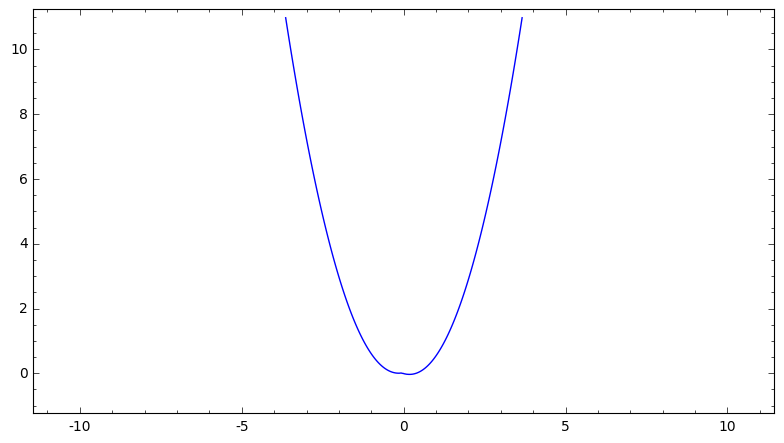

In [318]:
R.<x,y,z,t,u0,u1,u2>=QQ[]
surface = z-(x^2+x*y+y^4)
#s = singular.eval
#s('LIB "surf.lib";')
#s("ring r = 0,(x,y,z),dp;")
#s("surfer(" + str(surface) + ")")

surface_h = surface.homogenize(t)

X = matrix(R, [[x], [y], [z], [t]])
U = matrix(R, [[u0],[u1],[u2]])

# projection:
s=.05
r=10
proj_matrix = matrix(QQ, [[1,s,0,0],[0,s,1,0],[0,0,0,1]])
print(proj_matrix)

incidence = surface_h + ideal((proj_matrix*X).augment(U).minors(2))
incidence = surface_h + ideal(((proj_matrix*X)-U).list())

ramification = incidence + ideal(jacobian(incidence.gens(),(x,y,z,t)).minors(4))

outline = ramification.saturation(ideal(x,y,z,t))[0]
outline = outline.elimination_ideal((x,y,z,t))

print(outline)
outline=outline.subs(u2=1)
(outline.change_ring(QQ[u0,u1])).plot(plot_points=1000)#,algorithm='surf')

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
(outline.change_ring(QQ[u0,u1])).plot

In [ ]:
outline=outline.subs

In [127]:
sines = [plot(c*sin(x), (-2*pi,2*pi), color=Color(c,0,0), ymin=-1, ymax=1) for c in sxrange(0,1,.2)]
a = animate(sines)
a.save('test_animation.gif')

In [150]:
R.<x,y>=QQ[]
curve = ideal(y-x^3)
curve.plot(algorithm="surf",linewidth=50)

In [328]:
# condition for a polynomial to have 2+2 multiplicity/ have 3 multiplicity/ 

# for surfaces: conditions for a polynomial to have 4 multiplicity (flecnodal)
# have 3+2, 2+2+2 (ok). Intersection with plane: 3+ramification on y, 2+2+ramification on y

In [81]:
# subresultant
R.<s,t>=QQ[]

poly0 = s^2*t^4+t+3 
poly1 = s*t^3+s*t^2

poly0=poly0.polynomial(t)
poly1=poly1.polynomial(t)


print subresultant_2(poly0,poly1)

#show(poly.sylvester_matrix(poly.derivative(t), t))

subres = (poly.sylvester_matrix(poly.derivative(t), t)).delete_rows([2,6])
subres = subres.delete_columns([6])
#show(subres)

subres.nrows(),subres.ncols()

condition1 = subres.delete_columns([5]).determinant()
condition2 = subres.delete_columns([4]).determinant()

(3*s^2, s^2, s^4)


In [67]:
M=poly0.sylvester_matrix(poly1)
M.delete_rows?

In [ ]:
(poly0.sylvester_matrix(poly1)).delete_rows

In [62]:
poly0.sylvester_matrix(poly1).delete_rows(?)

SyntaxError: invalid syntax (<ipython-input-62-7debf33a83f8>, line 1)

In [ ]:
poly0.sylvester_matrix(poly1).delete_rows

In [4]:
R.<d>=QQ[]
S.<t1,t2>=R[]

In [20]:
d*t1*((d-1)*t1+t2)*((d-2)*t1+2*t2)#*((d-3)*t1+3*t2)

(d^3 - 3*d^2 + 2*d)*t1^3 + (3*d^2 - 4*d)*t1^2*t2 + 2*d*t1*t2^2

TypeError: no conversion of this ring to a Singular ring defined

In [227]:
load("nodal3.sobj")

Ideal (a3^3 - 4*a2*a3*a4 + 8*a1*a4^2, a2*a3^2 - 4*a2^2*a4 + 2*a1*a3*a4 + 16*a0*a4^2, a1*a3^2 - 4*a1*a2*a4 + 8*a0*a3*a4, a0*a3^2 - a1^2*a4, a1^2*a3 - 4*a0*a2*a3 + 8*a0*a1*a4, a1^2*a2 - 4*a0*a2^2 + 2*a0*a1*a3 + 16*a0^2*a4, a1^3 - 4*a0*a1*a2 + 8*a0^2*a3) of Multivariate Polynomial Ring in a0, a1, a2, a3, a4 over Rational Field

In [ ]:
R1.<x0, x1, x2, x3, p01, p02, p03, p12, p13, p23, t> = QQ[]

# two points on u0x0+u1x1+u2x2=0
P = vector(R1,[p01,0,-p12,-p13])
Q = vector(R1,[0, p01, p02, p03])

F1 = S_F.change_ring(R1)
poly = (F1.subs(x0=((P + t * Q)[0]), x1=((P + t * Q)[1]), 
                x2=((P + t * Q)[2]), x3 =((P + t * Q)[3]))).gens()[0]


hurwitz_p = poly.discriminant(t)
hurwitz = ideal(hurwitz_p)+ideal(p01*p23-p02*p13+p03*p12) #.change_ring(R2)

hurwitz = hurwitz.saturation(ideal(p01))[0]

print "Degree of Hurwitz: ", hurwitz.gens()[1].degree()
print hurwitz

In [41]:
def hessian_determinant(F):

    return ideal(jacobian(jacobian(F, (x0, x1, x2, x3)), (x0, x1, x2, x3)).determinant())

R1.<x0, x1, x2, x3, y0, y1, y2, y3> = K[]

F1 = (ideal(F).change_ring(R1)).gens()[0]

Y = matrix(R1,[[y0], [y1], [y2], [y3]])


hessian_matrix = jacobian(jacobian(F1, (x0,x1, x2, x3)), (x0,x1, x2, x3))


G0 = F1           
G1 = ideal((matrix(R1,jacobian(F1,(x0,x1,x2,x3)))*Y).list()).change_ring(R1)
G2 = ideal((Y.transpose()*hessian_matrix*Y).list()).change_ring(R1)
H = hessian_determinant(F1)

incidence = G0 + G1 + G2 + H

incidence = incidence.substitute(x0=1, y0=1)

#incidence = incidence.saturation(ideal(x0,x1,x2,x3))[0]
parabolic = incidence.elimination_ideal((x1,x2,x3))

print parabolic

KeyboardInterrupt: 

In [76]:
R1.<x0, x1, x2, x3, y0, y1, y2, y3> = K[]

F1 = (ideal(F).change_ring(R1)).gens()[0]
H = jacobian(jacobian(F1, (x0,x1, x2, x3)), (x0, x1, x2, x3))
J = jacobian(F1, (x0,x1, x2, x3))



X = matrix(R1,[[1], [x1], [x2], [x3]])
Y = matrix(R1,[[0], [y1], [y2], [y3]])

XY = X.augment(Y)
XYmin = XY.minors(2)

I = ideal(F1) + ideal(H.determinant()) + ideal((H*Y - J.transpose()).list())

#I = I.subs(x0=1)

parabolic = I.elimination_ideal((x0, x1, x2, x3))

parabolic = parabolic.change_ring(K[y0,y1,y2,y3])
print parabolic.hilbert_polynomial()



KeyboardInterrupt: 

In [68]:
print parabolic

Ideal (0) of Multivariate Polynomial Ring in y0, y1, y2, y3 over Rational Field
